# 05 – A Balaton vízállás-adatainak feltáró elemzése (EDA)

**Időszak:** 2016. szeptember 30. – 2026. szeptember 30.  
**Mérőállomás:** Siófok [2888]  
**Mért változó:** felszíni vízállás (cm)

## A notebook célja

A notebook a 04-es adatbetöltési folyamatban létrehozott, vízhőmérséklettől független, teljes vízállás-adatállomány feltáró elemzését végzi el.

A vizsgálat célja nem előrejelzés és nem ok-okozati magyarázat, hanem az adatállomány szerkezetének, időbeli lefedettségének, a vízállás eloszlásának és változékonyságának megismerése. Az eredmények alapján dönthető el, milyen további elemzések és modellek indokoltak.

## Fontos módszertani megjegyzések

- A 2016-os és a 2026-os naptári év **részleges év**. Az éves darabszámok közvetlen összehasonlítása ezért félrevezető lehet.
- A 2017–2025 közötti éveket teljes naptári évként kezeljük, de a tényleges időbélyegek alapján ezt is ellenőrizzük.
- Az eredeti mérési sorokat nem aggregáljuk és nem töröljük. Az időbeli összesítések külön, származtatott táblákban készülnek.
- A szélsőséges értékeket először csak megjelöljük és megvizsgáljuk; automatikusan nem távolítjuk el őket.
- A vízállás változása önmagában nem azonos a párolgással, és nem ad közvetlen információt a tó víztérfogatának változásáról.

## A vizsgálat fő részei

1. Adatbetöltés és alapellenőrzés
2. Időbeli lefedettség és mérési gyakoriság
3. A vízállás idősoros alakulása
4. Éves, havi és évszakos mintázatok
5. Eloszlás és szélsőértékek
6. Rövid távú változások és kiugró értékek
7. Eredmények és további elemzési kérdések

## 1. Könyvtárak és beállítások

A notebook a Git-projekt gyökérkönyvtárából futtatva a `data/processed` mappában keresi a 04-es notebook által létrehozott CSV-t. Ha más helyre mentetted az adatállományt, a `DATA_FILE` változót módosítsd.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# A notebook a repo notebooks/ mappájában van.
# A kód akkor is működik, ha a JupyterLabot a repo gyökeréből,
# és akkor is, ha közvetlenül a notebooks/ mappából indítod.
WORKING_DIR = Path.cwd()

if WORKING_DIR.name.lower() == "notebooks":
    PROJECT_ROOT = WORKING_DIR.parent
elif (WORKING_DIR / "notebooks").is_dir():
    PROJECT_ROOT = WORKING_DIR
else:
    raise FileNotFoundError(
        "Nem sikerült meghatározni a projekt gyökérkönyvtárát. "
        "Indítsd a JupyterLabot a repo gyökeréből vagy a notebooks mappából."
    )

DATA_FILE = PROJECT_ROOT / "data" / "processed" / "balaton_2016-2026_vizallas_teljes.csv"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

PARTIAL_YEARS = {2016, 2026}

print("Projekt gyökérkönyvtár:", PROJECT_ROOT)
print("Adatfájl:", DATA_FILE)
print("Adatfájl létezik:", DATA_FILE.exists())

Projekt gyökérkönyvtár: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT
Adatfájl: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\data\processed\balaton_2016-2026_vizallas_teljes.csv
Adatfájl létezik: True


## 2. Az adatállomány betöltése

A 04-es notebook kimeneti fájljának neve és helye a projektben rögzített. A CSV-t több lehetséges kódolással próbáljuk megnyitni. A dátum- és vízállás-oszlopot a program a lehetséges oszlopnevek alapján azonosítja; ha ez nem sikerül egyértelműen, a notebook megáll, és kiírja a tényleges oszlopneveket.

In [2]:
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Nem található az adatfájl: {DATA_FILE}\n"
        "Ellenőrizd, hogy a 04-es notebook lefutott-e, és a JupyterLabot a repo gyökeréből vagy a notebooks mappából indítottad-e."
    )

df_raw = None
last_error = None

for encoding in ["utf-8-sig", "utf-8", "cp1250", "latin1"]:
    try:
        df_raw = pd.read_csv(DATA_FILE, encoding=encoding, sep=None, engine="python")
        print("Sikeres beolvasás. Kódolás:", encoding)
        break
    except Exception as exc:
        last_error = exc

if df_raw is None:
    raise last_error

print("Sorok száma:", len(df_raw))
print("Oszlopok:", df_raw.columns.tolist())
display(df_raw.head())

Sikeres beolvasás. Kódolás: utf-8-sig
Sorok száma: 221802
Oszlopok: ['idopont', 'vizallas_cm', 'forras_fajl', 'forras_rekord_sorszama']


,idopont,vizallas_cm,forras_fajl,forras_rekord_sorszama
0,2016-09-30 00:30:00,113.00,2016-17.csv,1
1,2016-09-30 04:15:00,113.00,2016-17.csv,2
2,2016-09-30 06:45:00,115.00,2016-17.csv,3
3,2016-09-30 07:00:00,114.00,2016-17.csv,4
4,2016-09-30 07:15:00,113.00,2016-17.csv,5


### 2.1. Dátum- és vízállás-oszlop azonosítása

Az adatbetöltési notebook későbbi változataiban az oszlopnevek szabványosíthatók. Itt ezért több gyakori elnevezést is elfogadunk.

In [3]:
def normalize_colname(name):
    return (
        str(name).strip().lower()
        .replace("\\n", " ")
        .replace("_", " ")
        .replace("[", " ")
        .replace("]", " ")
    )

normalized = {col: normalize_colname(col) for col in df_raw.columns}

date_candidates = [
    col for col, norm in normalized.items()
    if norm in {"időpont", "idopont", "datum", "dátum", "datetime", "timestamp"}
    or "időpont" in norm or "idopont" in norm
]

level_candidates = [
    col for col, norm in normalized.items()
    if ("vízállás" in norm or "vizallas" in norm)
    and ("cm" in norm or norm in {"vízállás", "vizallas"})
]

if len(date_candidates) != 1 or len(level_candidates) != 1:
    raise ValueError(
        "Nem sikerült egyértelműen azonosítani a szükséges oszlopokat.\n"
        f"Dátumoszlop-jelöltek: {date_candidates}\n"
        f"Vízállásoszlop-jelöltek: {level_candidates}\n"
        f"Az összes oszlop: {df_raw.columns.tolist()}\n"
        "A következő cellában állítsd be kézzel a DATE_COL és LEVEL_COL változókat."
    )

DATE_COL = date_candidates[0]
LEVEL_COL = level_candidates[0]

print("Dátumoszlop:", DATE_COL)
print("Vízállás-oszlop:", LEVEL_COL)

Dátumoszlop: idopont
Vízállás-oszlop: vizallas_cm


## 3. Elemzési adatkeret létrehozása

Az elemzéshez két egységes oszlopot használunk: `idopont` és `vizallas_cm`. A forrásfájl és az eredeti sorszám oszlopait – ha rendelkezésre állnak – megtartjuk.

In [4]:
df = df_raw.copy()
df["idopont"] = pd.to_datetime(df[DATE_COL], errors="coerce", dayfirst=True)
df["vizallas_cm"] = pd.to_numeric(
    df[LEVEL_COL].astype(str).str.replace(",", ".", regex=False).str.strip(),
    errors="coerce"
)

# A hiányzó dátumú vagy vízállású sorok külön ellenőrzésre kerülnek.
invalid_date_count = int(df["idopont"].isna().sum())
invalid_level_count = int(df["vizallas_cm"].isna().sum())

analysis_df = df.dropna(subset=["idopont", "vizallas_cm"]).copy()
analysis_df = analysis_df.sort_values("idopont").reset_index(drop=True)

analysis_df["ev"] = analysis_df["idopont"].dt.year
analysis_df["honap"] = analysis_df["idopont"].dt.month
analysis_df["nap"] = analysis_df["idopont"].dt.date
analysis_df["het_napja"] = analysis_df["idopont"].dt.day_name()

print(f"Eredeti sorok: {len(df_raw):,}")
print(f"Hibás/hiányzó időpont: {invalid_date_count:,}")
print(f"Hibás/hiányzó vízállás: {invalid_level_count:,}")
print(f"Elemzésbe bevont sorok: {len(analysis_df):,}")
print("Első időpont:", analysis_df["idopont"].min())
print("Utolsó időpont:", analysis_df["idopont"].max())

display(analysis_df.head())
display(analysis_df.describe(include="all").T)

C:\Users\Zoli\AppData\Local\Temp\ipykernel_8576\170120774.py:2: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df["idopont"] = pd.to_datetime(df[DATE_COL], errors="coerce", dayfirst=True)


Eredeti sorok: 221,802
Hibás/hiányzó időpont: 0
Hibás/hiányzó vízállás: 0
Elemzésbe bevont sorok: 221,802
Első időpont: 2016-09-30 00:30:00
Utolsó időpont: 2026-09-30 03:00:00


,idopont,vizallas_cm,forras_fajl,forras_rekord_sorszama,ev,honap,nap,het_napja
0,2016-09-30 00:30:00,113.00,2016-17.csv,1,2016,9,2016-09-30,Friday
1,2016-09-30 04:15:00,113.00,2016-17.csv,2,2016,9,2016-09-30,Friday
2,2016-09-30 06:45:00,115.00,2016-17.csv,3,2016,9,2016-09-30,Friday
3,2016-09-30 07:00:00,114.00,2016-17.csv,4,2016,9,2016-09-30,Friday
4,2016-09-30 07:15:00,113.00,2016-17.csv,5,2016,9,2016-09-30,Friday


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
idopont,221802,NaN,NaN,NaN,2023-02-17 03:45:30.783401472,2016-09-30 00:30:00,2021-12-20 11:52:30,2023-08-04 09:37:30,2025-03-02 08:11:15,2026-09-30 03:00:00,NaN
vizallas_cm,"221,802.00",NaN,NaN,NaN,100.32,27.00,89.00,103.00,115.00,154.00,19.73
forras_fajl,221802,10,2023-24.csv,35209,NaN,NaN,NaN,NaN,NaN,NaN,NaN
forras_rekord_sorszama,"221,802.00",NaN,NaN,NaN,"14,187.45",1.00,"5,546.00","11,554.00","22,644.00","35,209.00","10,091.66"
ev,"221,802.00",NaN,NaN,NaN,"2,022.64","2,016.00","2,021.00","2,023.00","2,025.00","2,026.00",2.60
honap,"221,802.00",NaN,NaN,NaN,6.42,1.00,4.00,6.00,9.00,12.00,3.37
nap,221802,3653,2024-09-30,192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
het_napja,221802,7,Monday,31977,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Adatminőségi ellenőrzések

Ebben a részben a hiányzó értékeket, a duplikált időpontokat, az időbeli rendezettséget és az alapvető értéktartományt vizsgáljuk. A duplikált időpont önmagában még nem bizonyít hibát: lehet azonos időpontra rögzített több mérés is, ezért először csak kimutatjuk.

In [5]:
quality_summary = pd.DataFrame({
    "mutato": [
        "Eredeti sorok száma",
        "Elemzésbe bevont sorok száma",
        "Hiányzó időpont",
        "Hiányzó / nem numerikus vízállás",
        "Duplikált időpontú sorok",
        "Egyedi időpontok száma",
        "Egyedi vízállásértékek száma",
        "Időpontok nem növekvő sorrendben az eredeti fájlban"
    ],
    "ertek": [
        len(df_raw),
        len(analysis_df),
        invalid_date_count,
        invalid_level_count,
        int(analysis_df.duplicated("idopont", keep=False).sum()),
        int(analysis_df["idopont"].nunique()),
        int(analysis_df["vizallas_cm"].nunique()),
        int((df["idopont"].dropna().diff().dropna() < pd.Timedelta(0)).sum())
    ]
})

display(quality_summary)
quality_summary.to_csv(REPORT_DIR / "05_adatminosegi_osszefoglalo.csv", index=False, encoding="utf-8-sig")

duplicate_times = (
    analysis_df[analysis_df.duplicated("idopont", keep=False)]
    .sort_values("idopont")
)
print("Duplikált időpontú rekordok:", len(duplicate_times))
display(duplicate_times.head(20))

,mutato,ertek
0,Eredeti sorok száma,221802
1,Elemzésbe bevont sorok száma,221802
2,Hiányzó időpont,0
3,Hiányzó / nem numerikus vízállás,0
4,Duplikált időpontú sorok,1056
5,Egyedi időpontok száma,221274
6,Egyedi vízállásértékek száma,125
7,Időpontok nem növekvő sorrendben az eredeti fá...,12


Duplikált időpontú rekordok: 1056


,idopont,vizallas_cm,forras_fajl,forras_rekord_sorszama,ev,honap,nap,het_napja
10657,2017-09-30 00:30:00,93.00,2017-18.csv,1,2017,9,2017-09-30,Saturday
10658,2017-09-30 00:30:00,93.00,2016-17.csv,10658,2017,9,2017-09-30,Saturday
10659,2017-09-30 02:00:00,91.00,2017-18.csv,2,2017,9,2017-09-30,Saturday
10660,2017-09-30 02:00:00,91.00,2016-17.csv,10659,2017,9,2017-09-30,Saturday
10661,2017-09-30 03:45:00,91.00,2016-17.csv,10660,2017,9,2017-09-30,Saturday
10662,2017-09-30 03:45:00,91.00,2017-18.csv,3,2017,9,2017-09-30,Saturday
10663,2017-09-30 05:15:00,91.00,2016-17.csv,10661,2017,9,2017-09-30,Saturday
10664,2017-09-30 05:15:00,91.00,2017-18.csv,4,2017,9,2017-09-30,Saturday
10666,2017-09-30 06:00:00,91.00,2017-18.csv,5,2017,9,2017-09-30,Saturday
10665,2017-09-30 06:00:00,91.00,2016-17.csv,10662,2017,9,2017-09-30,Saturday


### 4.1. Vízállásértékek alapvető tartománya

A minimumot és maximumot ellenőrizzük, de ebben a fázisban nem állítunk fel automatikus érvényességi határokat. A fizikai és mérőállomás-specifikus határok megállapításához hiteles mérési dokumentáció szükséges.

,vizallas_cm
count,"221,802.00"
mean,100.32
std,19.73
min,27.00
1%,40.00
5%,68.00
25%,89.00
50%,103.00
75%,115.00
95%,127.00


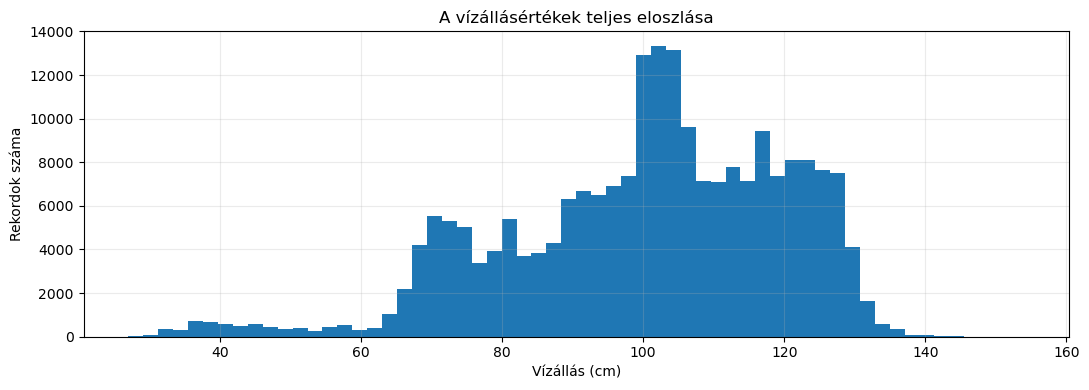

In [6]:
display(
    analysis_df["vizallas_cm"]
    .describe(percentiles=[.01, .05, .25, .50, .75, .95, .99])
    .to_frame("vizallas_cm")
)

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(analysis_df["vizallas_cm"].dropna(), bins=60)
ax.set_title("A vízállásértékek teljes eloszlása")
ax.set_xlabel("Vízállás (cm)")
ax.set_ylabel("Rekordok száma")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Időbeli lefedettség és mérési gyakoriság

A fájlméret és a rekordok száma önmagában nem bizonyítja a mérési gyakoriság változását. Ehhez az egymást követő időbélyegek közötti időtartamot kell vizsgálni.

A 2016-os és 2026-os részleges év éves rekorddarabszáma nem hasonlítható közvetlenül a teljes évekhez.

,ev,rekordok,elso_meres,utolso_meres,napi_egyedi_meresnapok,idoszak_teljessege,megjegyzes
0,2016,2639,2016-09-30 00:30:00,2016-12-31 21:15:00,93,részleges év,A rekorddarabszám nem hasonlítható közvetlenül...
1,2017,10827,2017-01-01 00:00:00,2017-12-31 23:30:00,365,teljes év – ellenőrizendő,
2,2018,9943,2018-01-01 00:00:00,2018-12-31 21:45:00,365,teljes év – ellenőrizendő,
3,2019,10603,2019-01-01 00:15:00,2019-12-31 23:30:00,365,teljes év – ellenőrizendő,
4,2020,10675,2020-01-01 00:00:00,2020-12-31 22:00:00,366,teljes év – ellenőrizendő,
5,2021,11106,2021-01-01 03:30:00,2021-12-31 23:45:00,365,teljes év – ellenőrizendő,
6,2022,34453,2022-01-01 00:15:00,2022-12-31 23:45:00,365,teljes év – ellenőrizendő,
7,2023,35105,2023-01-01 00:00:00,2023-12-31 23:00:00,365,teljes év – ellenőrizendő,
8,2024,35211,2024-01-01 00:15:00,2024-12-31 23:45:00,366,teljes év – ellenőrizendő,
9,2025,35123,2025-01-01 00:00:00,2025-12-31 23:45:00,365,teljes év – ellenőrizendő,


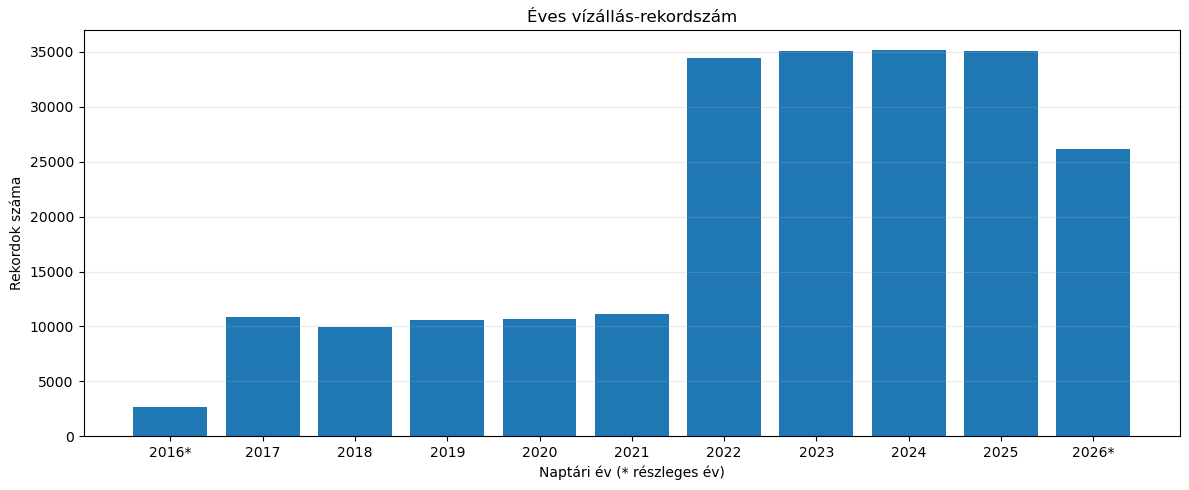

In [7]:
annual_counts = (
    analysis_df.groupby("ev")
    .agg(
        rekordok=("vizallas_cm", "size"),
        elso_meres=("idopont", "min"),
        utolso_meres=("idopont", "max"),
        napi_egyedi_meresnapok=("nap", "nunique")
    )
    .reset_index()
)

annual_counts["idoszak_teljessege"] = np.where(
    annual_counts["ev"].isin(PARTIAL_YEARS), "részleges év", "teljes év – ellenőrizendő"
)
annual_counts["megjegyzes"] = np.where(
    annual_counts["ev"].isin(PARTIAL_YEARS),
    "A rekorddarabszám nem hasonlítható közvetlenül a teljes évekéhez.",
    ""
)

display(annual_counts)
annual_counts.to_csv(REPORT_DIR / "05_eves_adatlefedettseg.csv", index=False, encoding="utf-8-sig")

plot_labels = [
    f"{int(row.ev)}*" if row.ev in PARTIAL_YEARS else str(int(row.ev))
    for row in annual_counts.itertuples()
]
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(plot_labels, annual_counts["rekordok"])
ax.set_title("Éves vízállás-rekordszám")
ax.set_xlabel("Naptári év (* részleges év)")
ax.set_ylabel("Rekordok száma")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

,idoeltelt
count,221801
mean,0 days 00:23:42.634704081
std,0 days 00:34:57.547095859
min,0 days 00:00:00
25%,0 days 00:15:00
50%,0 days 00:15:00
75%,0 days 00:15:00
max,1 days 00:00:00


Leggyakoribb mérési időközök:


,idoeltelt,darab
0,0 days 00:15:00,184481
1,0 days 00:30:00,15713
2,0 days 00:45:00,6526
3,0 days 01:00:00,3964
4,0 days 01:15:00,2219
5,0 days 01:30:00,1907
6,0 days 01:45:00,1222
7,0 days 02:00:00,1033
8,0 days 02:15:00,723
9,0 days 02:30:00,646


,ev,median_perc,atlag_perc,minimum_perc,maximum_perc
0,2016,30.00,50.69,15.00,705.00
1,2017,30.00,48.56,0.00,"1,440.00"
2,2018,30.00,52.85,0.00,"1,305.00"
3,2019,30.00,49.58,0.00,855.00
4,2020,30.00,49.36,0.00,"1,440.00"
5,2021,30.00,47.34,0.00,810.00
6,2022,15.00,15.26,0.00,270.00
7,2023,15.00,14.97,0.00,270.00
8,2024,15.00,14.97,0.00,75.00
9,2025,15.00,14.96,0.00,75.00


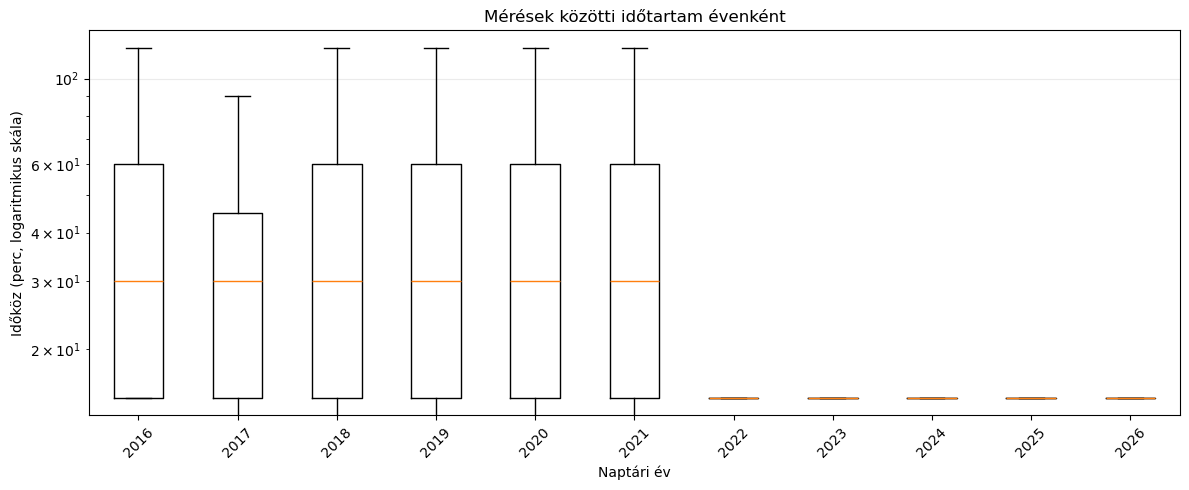

In [8]:
# Az időbélyegek közötti különbség az eredeti, időrendbe rendezett adatsorban.
time_diffs = analysis_df["idopont"].diff().dropna()
interval_summary = time_diffs.describe()
display(interval_summary.to_frame("idoeltelt"))

print("Leggyakoribb mérési időközök:")
display(time_diffs.value_counts().head(15).rename_axis("idoeltelt").reset_index(name="darab"))

analysis_df["elozo_meres_ota_perc"] = (
    analysis_df["idopont"].diff().dt.total_seconds() / 60
)

interval_by_year = (
    analysis_df.groupby("ev")["elozo_meres_ota_perc"]
    .agg(
        median_perc="median",
        atlag_perc="mean",
        minimum_perc="min",
        maximum_perc="max"
    )
    .reset_index()
)
display(interval_by_year)
interval_by_year.to_csv(REPORT_DIR / "05_meresi_idokoz_evenkent.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(
    [analysis_df.loc[analysis_df["ev"] == year, "elozo_meres_ota_perc"].dropna()
     for year in sorted(analysis_df["ev"].unique())],
    tick_labels=sorted(analysis_df["ev"].unique()),
    showfliers=False
)
ax.set_title("Mérések közötti időtartam évenként")
ax.set_xlabel("Naptári év")
ax.set_ylabel("Időköz (perc, logaritmikus skála)")
ax.set_yscale("log")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 5.1. Napi lefedettség és mérési darabszám

A napi rekorddarabszám megmutatja, hogy az egyes napokon hány mérés szerepel. Ezzel azonosíthatók a mérés nélküli napok, illetve a mérési sűrűség változásai. A hiányzó napok kimutatásához a teljes naptári dátumtartományt létrehozzuk.

Mérés nélküli napok száma: 0


,napi_rekordszam
count,"3,653.00"
mean,60.72
std,35.14
min,1.00
25%,27.00
50%,54.00
75%,96.00
max,192.00


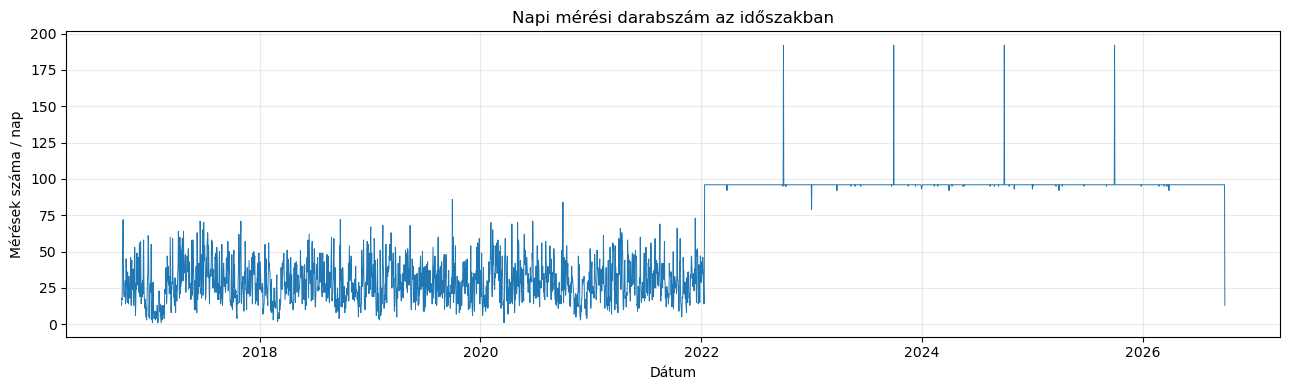

In [9]:
daily_count = analysis_df.groupby("nap").size().rename("rekordok_szama")
all_days = pd.date_range(
    analysis_df["idopont"].min().normalize(),
    analysis_df["idopont"].max().normalize(),
    freq="D"
)
daily_count = daily_count.reindex(all_days.date, fill_value=0)
daily_count.index.name = "nap"

print("Mérés nélküli napok száma:", int((daily_count == 0).sum()))
display(daily_count.describe().to_frame("napi_rekordszam"))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(pd.to_datetime(daily_count.index), daily_count.values, linewidth=0.7)
ax.set_title("Napi mérési darabszám az időszakban")
ax.set_xlabel("Dátum")
ax.set_ylabel("Mérések száma / nap")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

daily_count.rename("rekordok_szama").to_csv(
    REPORT_DIR / "05_napi_meresi_darabszam.csv",
    encoding="utf-8-sig"
)

### 5.2. Éves mérési gyakoriság és a napi 96 mérés vizsgálata

A következő összesítés számszerűsíti az egyes évek napi mérési gyakoriságát. A számítás a teljes lefedett naptári napokat veszi figyelembe, a mérés nélküli napokat is beleértve.

Minden évre meghatározzuk:
- a napi mérésszám mediánját;
- a napi mérésszám átlagát;
- a pontosan 96 mérést tartalmazó napok számát és arányát;
- a 96-nál kevesebb mérést tartalmazó napok számát;
- a 96-nál több mérést tartalmazó napok számát.

A 96 mérés/nap 15 perces mérési időköznek felel meg, ha a nap mind a 24 órájában folyamatos a mérés. A 96-os értéktől való eltérés önmagában nem bizonyít hibát vagy konkrét műszaki változást; a mérési időközök és a forrásadatok további vizsgálata szükséges.

A 2016-os és 2026-os év részleges. Ezeknél a nevező az adatállományban ténylegesen lefedett naptári napok száma, nem a teljes év 365/366 napja.

,ev,idoszak_teljessege,lefedett_napok,napi_meresszam_median,napi_meresszam_atlag,napok_96_meressel,96_mereses_napok_aranya_pct,napok_96_alatt,napok_96_felett
0,2016,részleges év,93,25.00,28.38,0,0.00,93,0
1,2017,teljes év – ellenőrizendő,365,28.00,29.66,0,0.00,365,0
2,2018,teljes év – ellenőrizendő,365,26.00,27.24,0,0.00,365,0
3,2019,teljes év – ellenőrizendő,365,28.00,29.05,0,0.00,365,0
4,2020,teljes év – ellenőrizendő,366,28.00,29.17,0,0.00,366,0
5,2021,teljes év – ellenőrizendő,365,29.00,30.43,0,0.00,365,0
6,2022,teljes év – ellenőrizendő,365,96.00,94.39,349,95.62,15,1
7,2023,teljes év – ellenőrizendő,365,96.00,96.18,354,96.99,10,1
8,2024,teljes év – ellenőrizendő,366,96.00,96.20,350,95.63,15,1
9,2025,teljes év – ellenőrizendő,365,96.00,96.23,356,97.53,8,1


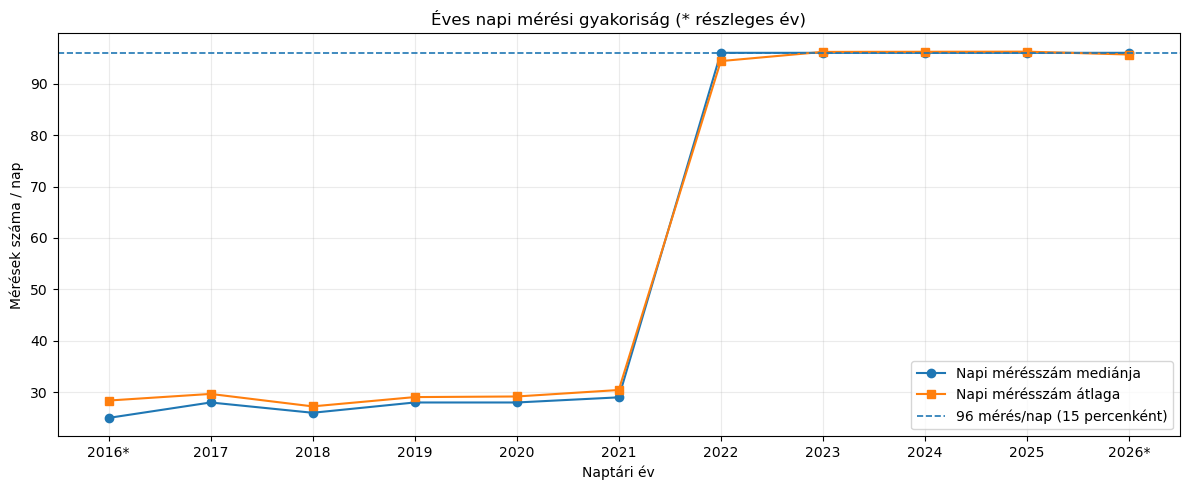

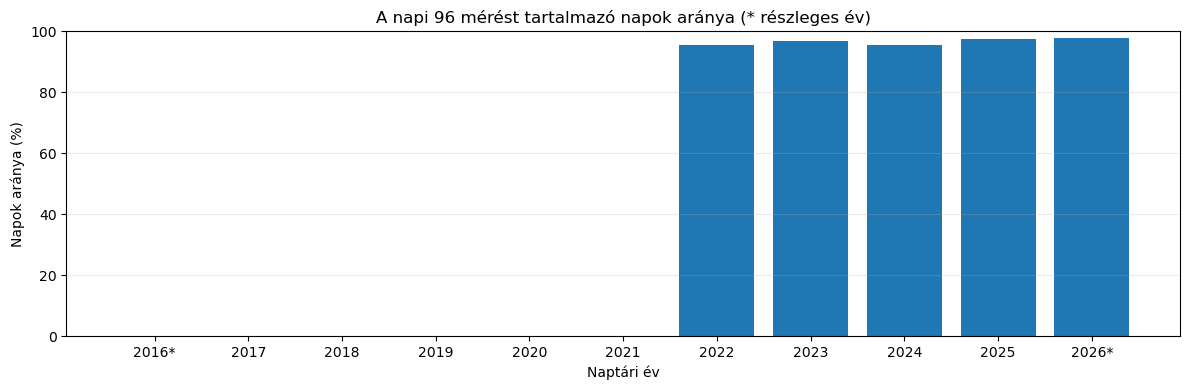

Éves mérési gyakoriság mentve: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\reports\05_eves_meresi_gyakorisag.csv
Ábrák mentve: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\reports\figures\05_annual_daily_measurement_frequency.png és C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\reports\figures\05_96_measurements_daily_share.png


In [10]:
# Napi mérésszám-adatokból éves gyakorisági összesítés.
daily_frequency = daily_count.rename("napi_meresek").to_frame()
daily_frequency.index = pd.to_datetime(daily_frequency.index)
daily_frequency["ev"] = daily_frequency.index.year

annual_frequency = (
    daily_frequency.groupby("ev")["napi_meresek"]
    .agg(
        lefedett_napok="count",
        napi_meresszam_median="median",
        napi_meresszam_atlag="mean",
        napok_96_meressel=lambda s: int((s == 96).sum()),
        napok_96_alatt=lambda s: int((s < 96).sum()),
        napok_96_felett=lambda s: int((s > 96).sum()),
    )
    .reset_index()
)

annual_frequency["96_mereses_napok_aranya_pct"] = (
    annual_frequency["napok_96_meressel"]
    / annual_frequency["lefedett_napok"] * 100
).round(2)

annual_frequency["idoszak_teljessege"] = np.where(
    annual_frequency["ev"].isin(PARTIAL_YEARS),
    "részleges év",
    "teljes év – ellenőrizendő"
)

# Oszlopok rendezése az áttekinthető megjelenítéshez.
annual_frequency = annual_frequency[
    [
        "ev",
        "idoszak_teljessege",
        "lefedett_napok",
        "napi_meresszam_median",
        "napi_meresszam_atlag",
        "napok_96_meressel",
        "96_mereses_napok_aranya_pct",
        "napok_96_alatt",
        "napok_96_felett",
    ]
]

display(annual_frequency.round(2))

annual_frequency.to_csv(
    REPORT_DIR / "05_eves_meresi_gyakorisag.csv",
    index=False,
    encoding="utf-8-sig"
)

# Ábra 1: a napi mérésszám éves mediánja és átlaga.
xlabels = [
    f"{int(row.ev)}*" if row.ev in PARTIAL_YEARS else str(int(row.ev))
    for row in annual_frequency.itertuples()
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    xlabels,
    annual_frequency["napi_meresszam_median"],
    marker="o",
    label="Napi mérésszám mediánja"
)
ax.plot(
    xlabels,
    annual_frequency["napi_meresszam_atlag"],
    marker="s",
    label="Napi mérésszám átlaga"
)
ax.axhline(96, linestyle="--", linewidth=1.2, label="96 mérés/nap (15 percenként)")
ax.set_title("Éves napi mérési gyakoriság (* részleges év)")
ax.set_xlabel("Naptári év")
ax.set_ylabel("Mérések száma / nap")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "05_annual_daily_measurement_frequency.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Ábra 2: a pontosan 96 méréses napok aránya.
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(
    xlabels,
    annual_frequency["96_mereses_napok_aranya_pct"]
)
ax.set_title("A napi 96 mérést tartalmazó napok aránya (* részleges év)")
ax.set_xlabel("Naptári év")
ax.set_ylabel("Napok aránya (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "05_96_measurements_daily_share.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print(
    "Éves mérési gyakoriság mentve:",
    REPORT_DIR / "05_eves_meresi_gyakorisag.csv"
)
print(
    "Ábrák mentve:",
    FIGURE_DIR / "05_annual_daily_measurement_frequency.png",
    "és",
    FIGURE_DIR / "05_96_measurements_daily_share.png"
)

## 6. A vízállás idősoros alakulása

Először az összes eredeti mérési pontot jelenítjük meg. A nagy adatsűrűség miatt külön ábrán napi átlagot és gördülő átlagot is készítünk. Ezek az összesített sorok az áttekinthetőséget szolgálják, nem írják felül az eredeti adatokat.

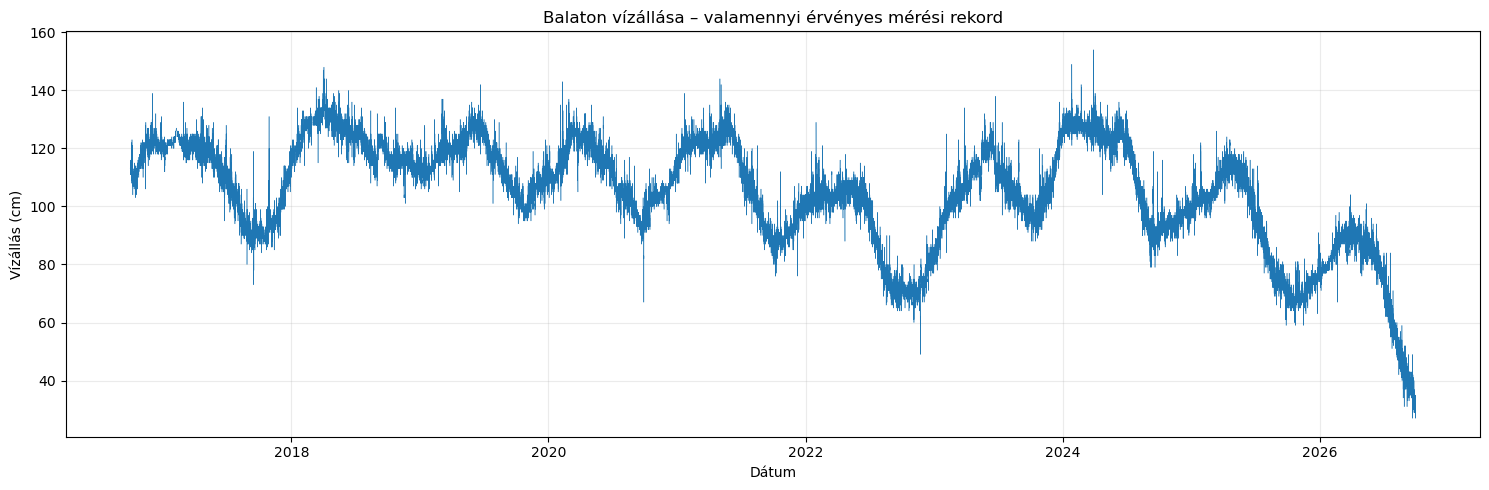

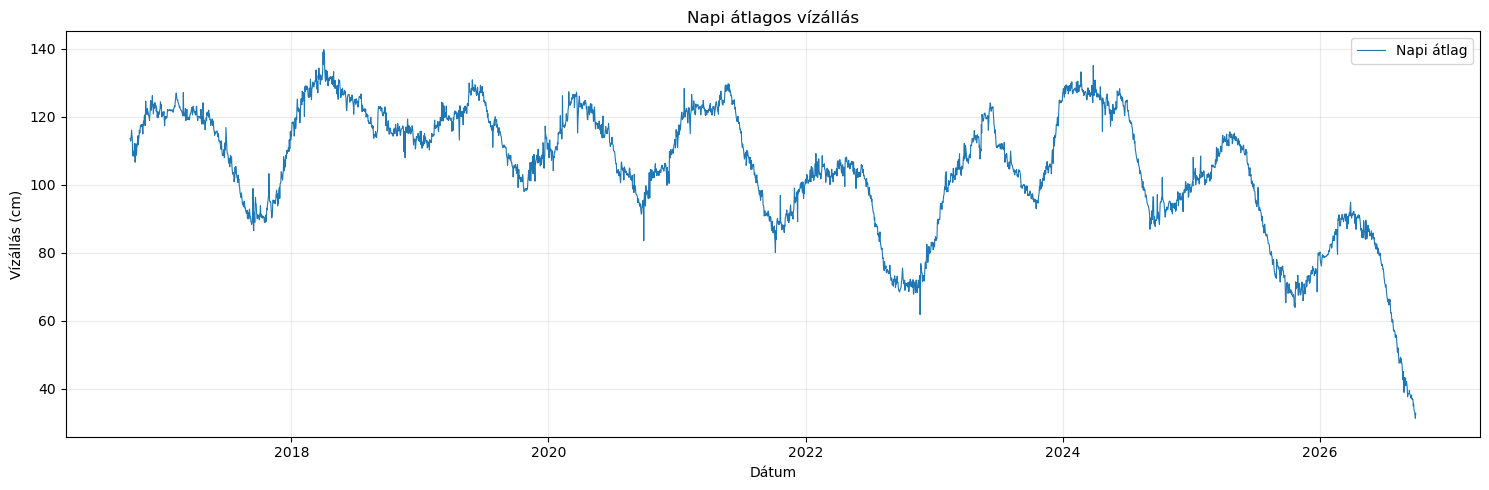

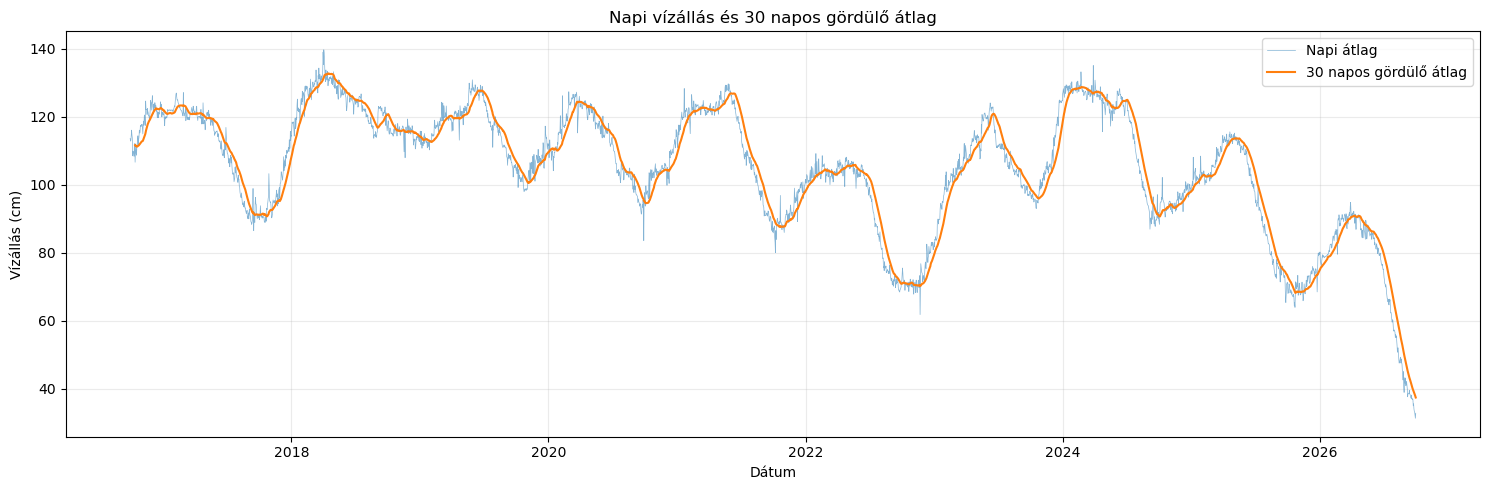

In [11]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(analysis_df["idopont"], analysis_df["vizallas_cm"], linewidth=0.35)
ax.set_title("Balaton vízállása – valamennyi érvényes mérési rekord")
ax.set_xlabel("Dátum")
ax.set_ylabel("Vízállás (cm)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

daily_level = (
    analysis_df.set_index("idopont")["vizallas_cm"]
    .resample("D")
    .agg(["mean", "min", "max", "count"])
)
daily_level.columns = ["napi_atlag_cm", "napi_min_cm", "napi_max_cm", "meresek_szama"]

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_level.index, daily_level["napi_atlag_cm"], linewidth=0.8, label="Napi átlag")
ax.set_title("Napi átlagos vízállás")
ax.set_xlabel("Dátum")
ax.set_ylabel("Vízállás (cm)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

daily_level["30_napos_gordulo_atlag"] = daily_level["napi_atlag_cm"].rolling(
    window=30, min_periods=15
).mean()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_level.index, daily_level["napi_atlag_cm"], linewidth=0.5, alpha=0.55, label="Napi átlag")
ax.plot(daily_level.index, daily_level["30_napos_gordulo_atlag"], linewidth=1.5, label="30 napos gördülő átlag")
ax.set_title("Napi vízállás és 30 napos gördülő átlag")
ax.set_xlabel("Dátum")
ax.set_ylabel("Vízállás (cm)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

daily_level.to_csv(REPORT_DIR / "05_napi_vizallas_osszesites.csv", encoding="utf-8-sig")

## 7. Éves vízállás-statisztikák

Az éves minimum, maximum, átlag, medián és szórás az éves eloszlásról ad képet. A 2016-os és 2026-os részleges éveket az éves statisztikai táblázatban feltüntetjük.

## 7.1. Éves minimum- és maximumértékek trendje – csak teljes évek

A következő diagram kizárólag a teljes naptári éveket, 2017–2025-öt használja.

A diagram elemei:
- éves minimumértékek és lineáris trendvonaluk;
- éves maximumértékek és lineáris trendvonaluk;
- a minimumot és maximumot összekötő függőleges vonal;
- az éves minimum és maximum értéke, valamint a mérés dátuma.

A függőleges vonal hossza az adott évben megfigyelt vízállás-terjedelmet mutatja:

\[
\Delta H_{év}=H_{maximum,év}-H_{minimum,év}
\]

Ez a vízállás-terjedelem nem azonos a tó víztérfogat-változásával.

A diagram a futtatás után a `reports/figures/05_annual_water_level_extremes_trends.png` fájlba is mentésre kerül.


### A minimum- és maximumtrend ábrája

A következő kódcellát futtasd le az ábra megjelenítéséhez és PNG-fájlba mentéséhez.

,ev,rekordok,minimum,maximum,atlag,median,szoras,Q1,Q3,idoszak_teljessege
0,2016,2639,103.00,139.00,118.62,120.00,5.32,115.00,122.00,részleges év
1,2017,10827,73.00,136.00,107.77,109.00,11.71,96.00,119.00,teljes év – ellenőrizendő
2,2018,9943,101.00,148.00,122.70,123.00,6.70,117.00,128.00,teljes év – ellenőrizendő
3,2019,10603,94.00,142.00,115.37,116.00,8.11,109.00,121.00,teljes év – ellenőrizendő
4,2020,10675,67.00,143.00,111.47,112.00,9.72,104.00,119.00,teljes év – ellenőrizendő
5,2021,11106,76.00,144.00,110.03,114.00,14.23,97.00,123.00,teljes év – ellenőrizendő
6,2022,34453,49.00,129.00,89.75,95.00,14.88,74.00,104.00,teljes év – ellenőrizendő
7,2023,35105,78.00,138.00,106.19,105.00,9.27,100.00,113.00,teljes év – ellenőrizendő
8,2024,35211,79.00,154.00,112.39,120.00,15.24,96.00,126.00,teljes év – ellenőrizendő
9,2025,35123,59.00,126.00,91.52,97.00,17.04,74.00,107.00,teljes év – ellenőrizendő


,ev,minimum_datuma,minimum_cm,maximum_datuma,maximum_cm,eves_vizallas_terjedelem_cm
0,2017,2017-09-15 00:00:00,73.00,2017-02-28 13:30:00,136.00,63.00
1,2018,2018-11-20 09:30:00,101.00,2018-04-03 13:00:00,148.00,47.00
2,2019,2019-10-07 08:45:00,94.00,2019-06-22 19:15:00,142.00,48.00
3,2020,2020-09-28 05:30:00,67.00,2020-02-10 12:30:00,143.00,76.00
4,2021,2021-10-07 07:00:00,76.00,2021-05-02 10:45:00,144.00,68.00
5,2022,2022-11-22 21:30:00,49.00,2022-01-30 11:30:00,129.00,80.00
6,2023,2023-01-09 17:00:00,78.00,2023-06-23 20:45:00,138.00,60.00
7,2024,2024-09-06 08:45:00,79.00,2024-03-28 22:00:00,154.00,75.00
8,2025,2025-09-27 00:15:00,59.00,2025-03-13 14:15:00,126.00,67.00


OSError: [Errno 22] Invalid argument: 'C:\\Users\\Zoli\\Adatelemzéseim\\Balatoni_vízállás_2016-2026_GIT\\reports\\figures\\05_annual_water_level_extremes_trends.png'

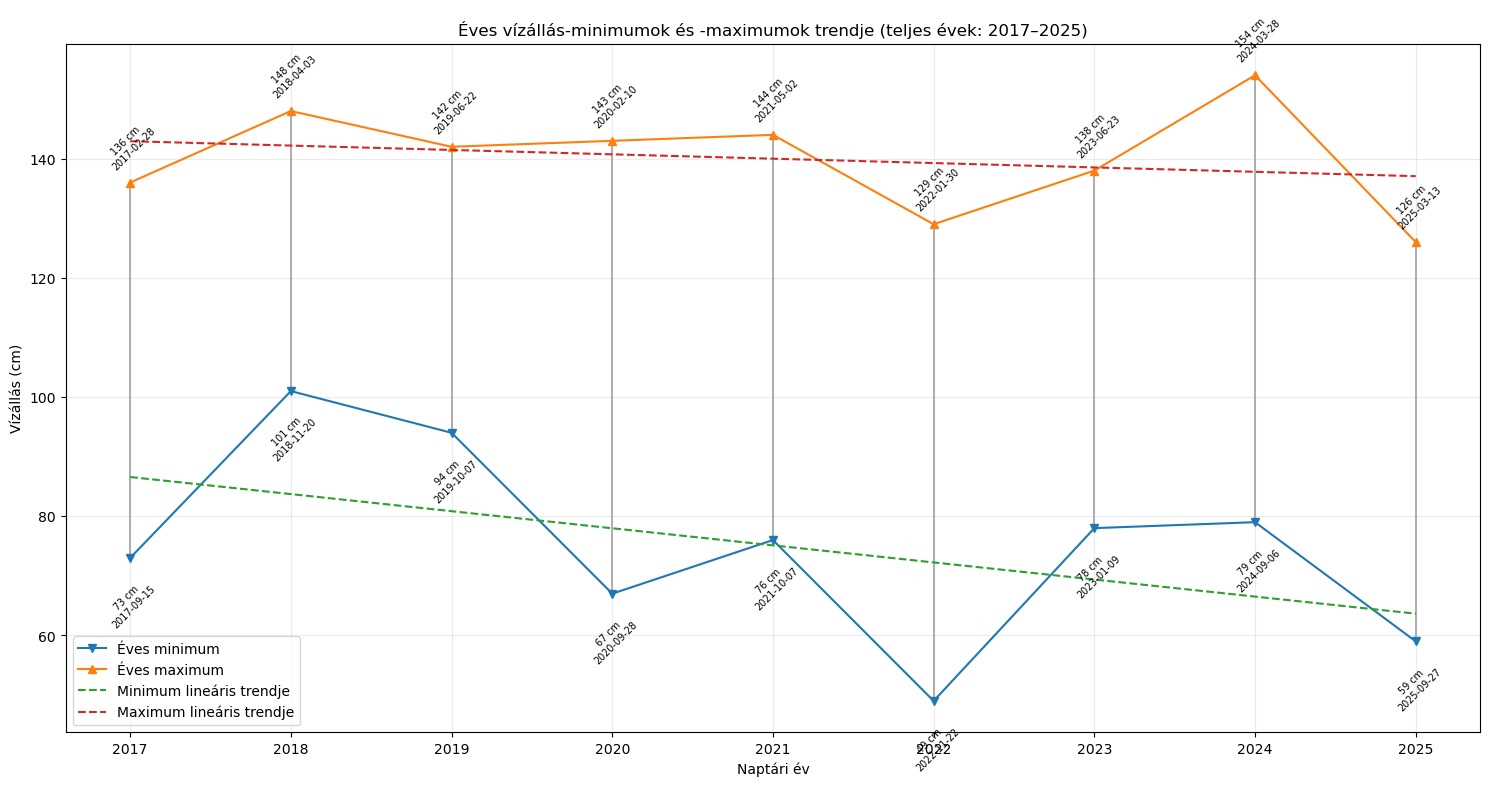

In [12]:
annual_stats = (
    analysis_df.groupby("ev")["vizallas_cm"]
    .agg(
        rekordok="count",
        minimum="min",
        maximum="max",
        atlag="mean",
        median="median",
        szoras="std",
    )
    .reset_index()
)

annual_quantiles = analysis_df.groupby("ev")["vizallas_cm"].quantile([0.25, 0.75]).unstack()
annual_quantiles.columns = ["Q1", "Q3"]
annual_stats = annual_stats.merge(annual_quantiles, on="ev", how="left")
annual_stats["idoszak_teljessege"] = np.where(
    annual_stats["ev"].isin(PARTIAL_YEARS), "részleges év", "teljes év – ellenőrizendő"
)

display(annual_stats.round(2))
annual_stats.to_csv(
    REPORT_DIR / "05_eves_vizallas_statisztikak.csv",
    index=False,
    encoding="utf-8-sig"
)

# A szélsőértékek pontos dátumának meghatározása.
full_year_data = analysis_df[~analysis_df["ev"].isin(PARTIAL_YEARS)].copy()

idx_min = full_year_data.groupby("ev")["vizallas_cm"].idxmin()
idx_max = full_year_data.groupby("ev")["vizallas_cm"].idxmax()

annual_min_dates = (
    full_year_data.loc[idx_min, ["ev", "idopont", "vizallas_cm"]]
    .rename(columns={
        "idopont": "minimum_datuma",
        "vizallas_cm": "minimum_cm"
    })
)
annual_max_dates = (
    full_year_data.loc[idx_max, ["ev", "idopont", "vizallas_cm"]]
    .rename(columns={
        "idopont": "maximum_datuma",
        "vizallas_cm": "maximum_cm"
    })
)

annual_extremes = (
    annual_min_dates.merge(annual_max_dates, on="ev")
    .sort_values("ev")
    .reset_index(drop=True)
)
annual_extremes["eves_vizallas_terjedelem_cm"] = (
    annual_extremes["maximum_cm"] - annual_extremes["minimum_cm"]
)

display(annual_extremes.round(2))
annual_extremes.to_csv(
    REPORT_DIR / "05_eves_minimum_maximum_datumok_teljes_evek.csv",
    index=False,
    encoding="utf-8-sig"
)

# Ábra: éves minimumok és maximumok, lineáris trendvonalakkal.
years = annual_extremes["ev"].to_numpy(dtype=float)
minimums = annual_extremes["minimum_cm"].to_numpy(dtype=float)
maximums = annual_extremes["maximum_cm"].to_numpy(dtype=float)

if len(years) < 2:
    raise ValueError("A trendvonalakhoz legalább két teljes naptári év adata szükséges.")

min_trend = np.poly1d(np.polyfit(years, minimums, 1))
max_trend = np.poly1d(np.polyfit(years, maximums, 1))
trend_years = np.linspace(years.min(), years.max(), 200)

fig, ax = plt.subplots(figsize=(15, 8))

ax.plot(
    years, minimums,
    marker="v", linewidth=1.5,
    label="Éves minimum"
)
ax.plot(
    years, maximums,
    marker="^", linewidth=1.5,
    label="Éves maximum"
)

ax.plot(
    trend_years, min_trend(trend_years),
    linestyle="--", linewidth=1.5,
    label="Minimum lineáris trendje"
)
ax.plot(
    trend_years, max_trend(trend_years),
    linestyle="--", linewidth=1.5,
    label="Maximum lineáris trendje"
)

# A minimum és maximum összekötése: a függőleges szakasz hossza az éves terjedelem.
for row in annual_extremes.itertuples():
    ax.vlines(
        x=row.ev,
        ymin=row.minimum_cm,
        ymax=row.maximum_cm,
        color="gray",
        alpha=0.65,
        linewidth=1.4,
        zorder=1
    )

    min_date = pd.Timestamp(row.minimum_datuma).strftime("%Y-%m-%d")
    max_date = pd.Timestamp(row.maximum_datuma).strftime("%Y-%m-%d")

    ax.annotate(
        f"{row.minimum_cm:.0f} cm\n{min_date}",
        xy=(row.ev, row.minimum_cm),
        xytext=(0, -12),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=7,
        rotation=45
    )
    ax.annotate(
        f"{row.maximum_cm:.0f} cm\n{max_date}",
        xy=(row.ev, row.maximum_cm),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=7,
        rotation=45
    )

ax.set_title("Éves vízállás-minimumok és -maximumok trendje (teljes évek: 2017–2025)")
ax.set_xlabel("Naptári év")
ax.set_ylabel("Vízállás (cm)")
ax.set_xticks(years)
ax.set_xticklabels([str(int(year)) for year in years])
ax.grid(alpha=0.25)
ax.legend(loc="best")
plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "05_annual_water_level_extremes_trends.png",
    dpi=200,
    bbox_inches="tight"
)
print("Az ábra mentve:", FIGURE_DIR / "05_annual_water_level_extremes_trends.png")
plt.show()


## 8. Havi és évszakos mintázatok

A havi átlagok és a hónapok szerinti eloszlások segítenek feltárni az ismétlődő éves mintázatokat. A havi összesítést az összes rendelkezésre álló évből készítjük el; ezért a 2016-os és 2026-os részleges időszak csak az érintett hónapokban szerepel.

In [ ]:
analysis_df["honap_nev"] = analysis_df["idopont"].dt.month
monthly_stats = (
    analysis_df.groupby("honap_nev")["vizallas_cm"]
    .agg(
        rekordok="count",
        atlag="mean",
        median="median",
        minimum="min",
        maximum="max",
        szoras="std"
    )
    .reindex(range(1, 13))
    .reset_index()
)
display(monthly_stats.round(2))
monthly_stats.to_csv(REPORT_DIR / "05_havi_vizallas_statisztikak.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly_stats["honap_nev"], monthly_stats["atlag"], marker="o")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Hónap")
ax.set_ylabel("Átlagos vízállás (cm)")
ax.set_title("Átlagos vízállás hónapok szerint – teljes vizsgált időszak")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Hónap × év átlagmátrix
month_year = analysis_df.pivot_table(
    index="honap_nev", columns="ev", values="vizallas_cm", aggfunc="mean"
)
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(month_year, aspect="auto", interpolation="nearest")
ax.set_yticks(range(12))
ax.set_yticklabels(range(1, 13))
ax.set_xticks(range(len(month_year.columns)))
ax.set_xticklabels(month_year.columns, rotation=45)
ax.set_xlabel("Év")
ax.set_ylabel("Hónap")
ax.set_title("Havi átlagos vízállás hőtérképe (cm)")
fig.colorbar(im, ax=ax, label="Vízállás (cm)")
plt.tight_layout()
plt.show()

def season_from_month(month):
    if month in [12, 1, 2]:
        return "Tél"
    if month in [3, 4, 5]:
        return "Tavasz"
    if month in [6, 7, 8]:
        return "Nyár"
    return "Ősz"

analysis_df["evszak"] = analysis_df["idopont"].dt.month.map(season_from_month)
season_stats = (
    analysis_df.groupby("evszak")["vizallas_cm"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .reindex(["Tél", "Tavasz", "Nyár", "Ősz"])
)
display(season_stats.round(2))
season_stats.to_csv(REPORT_DIR / "05_evszakos_vizallas_statisztikak.csv", encoding="utf-8-sig")

## 9. Eloszlás és szélsőértékek

Az eloszlás vizsgálatához hisztogramot és dobozdiagramot használunk. A szélső értékek listázása segít az események és az esetleges adathibák későbbi ellenőrzésében. A szélsőséges vízállás lehet valós hidrológiai esemény, ezért az automatikus statisztikai kiugróérték-jelölés nem jelent automatikus törlési szabályt.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(analysis_df["vizallas_cm"], bins=60)
axes[0].set_title("Vízállás eloszlása")
axes[0].set_xlabel("Vízállás (cm)")
axes[0].set_ylabel("Rekordok száma")
axes[0].grid(alpha=0.2)

axes[1].boxplot(analysis_df["vizallas_cm"], vert=True)
axes[1].set_title("Vízállás dobozdiagramja")
axes[1].set_ylabel("Vízállás (cm)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

lowest_records = analysis_df.nsmallest(20, "vizallas_cm")[
    ["idopont", "vizallas_cm"]
]
highest_records = analysis_df.nlargest(20, "vizallas_cm")[
    ["idopont", "vizallas_cm"]
]

print("20 legalacsonyabb mérés:")
display(lowest_records)
print("20 legmagasabb mérés:")
display(highest_records)

lowest_records.to_csv(REPORT_DIR / "05_legalacsonyabb_meresek.csv", index=False, encoding="utf-8-sig")
highest_records.to_csv(REPORT_DIR / "05_legmagasabb_meresek.csv", index=False, encoding="utf-8-sig")

## 10. Rövid távú változások és kiugró értékek

A különbség az egymást követő mérési rekordok között csak akkor értelmezhető megfelelően, ha a két mérés közötti időtartamot is figyelembe vesszük. Ezért kiszámítjuk a vízállás-változást centiméterben, valamint az órára vetített változást.

A mérési időközök változása miatt a rekordok közötti egyszerű különbség nem azonos hosszúságú időszakokat fedhet le.

In [ ]:
change_df = analysis_df[["idopont", "vizallas_cm"]].copy()
change_df["ido_perc"] = change_df["idopont"].diff().dt.total_seconds() / 60
change_df["valtozas_cm"] = change_df["vizallas_cm"].diff()
change_df["valtozas_cm_orankent"] = (
    change_df["valtozas_cm"] / (change_df["ido_perc"] / 60)
)
change_df = change_df.replace([np.inf, -np.inf], np.nan)

display(
    change_df[["ido_perc", "valtozas_cm", "valtozas_cm_orankent"]]
    .describe(percentiles=[.01, .05, .5, .95, .99]).T
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(change_df["idopont"], change_df["valtozas_cm"], linewidth=0.4)
ax.set_title("Vízállás-változás két egymást követő mérés között")
ax.set_xlabel("Dátum")
ax.set_ylabel("Változás (cm)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Robusztus jelölés: medián ± 6 × MAD-alapú robusztus szórás.
delta = change_df["valtozas_cm"].dropna()
delta_median = delta.median()
mad = (delta - delta_median).abs().median()
robust_sigma = 1.4826 * mad

if robust_sigma > 0:
    change_df["robosztus_kiugro"] = (
        (change_df["valtozas_cm"] - delta_median).abs() > 6 * robust_sigma
    )
else:
    change_df["robosztus_kiugro"] = False

flagged_changes = change_df[change_df["robosztus_kiugro"]].copy()
print("Robusztus szabállyal jelölt változások:", len(flagged_changes))
display(flagged_changes.head(30))

flagged_changes.to_csv(
    REPORT_DIR / "05_vizallasvaltozas_kiugro_jelolesek.csv",
    index=False,
    encoding="utf-8-sig"
)

## 11. Napi vízállás-ingadozás

A napon belüli minimum és maximum különbsége megmutatja, hogy az adott napon mekkora volt a megfigyelt vízállás-tartomány. Ezt csak a kellő számú méréssel rendelkező napokon érdemes értelmezni.

In [ ]:
daily_range = (
    analysis_df.groupby("nap")["vizallas_cm"]
    .agg(
        meresek_szama="count",
        napi_min="min",
        napi_max="max",
        napi_atlag="mean"
    )
)
daily_range["napi_terjedelem_cm"] = daily_range["napi_max"] - daily_range["napi_min"]

display(daily_range.describe().T)
display(daily_range.sort_values("napi_terjedelem_cm", ascending=False).head(20))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(pd.to_datetime(daily_range.index), daily_range["napi_terjedelem_cm"], linewidth=0.6)
ax.set_title("Napon belüli megfigyelt vízállás-terjedelem")
ax.set_xlabel("Dátum")
ax.set_ylabel("Napi maximum – minimum (cm)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

daily_range.to_csv(REPORT_DIR / "05_napi_vizallas_terjedelem.csv", encoding="utf-8-sig")

## 12. Eredmények összefoglalása és következő lépések

Az alábbi cella automatikusan előállít néhány alapvető, leíró adatot. Ezek nem helyettesítik az ábrák és az adatminőségi ellenőrzések szakmai értelmezését.

In [ ]:
summary = {
    "rekordok_szama": len(analysis_df),
    "elso_idopont": analysis_df["idopont"].min(),
    "utolso_idopont": analysis_df["idopont"].max(),
    "vizallas_min_cm": analysis_df["vizallas_cm"].min(),
    "vizallas_max_cm": analysis_df["vizallas_cm"].max(),
    "vizallas_atlag_cm": analysis_df["vizallas_cm"].mean(),
    "vizallas_median_cm": analysis_df["vizallas_cm"].median(),
    "vizallas_szoras_cm": analysis_df["vizallas_cm"].std(),
    "duplikalt_idopontu_sorok": int(analysis_df.duplicated("idopont", keep=False).sum()),
    "reszleges_evek": "2016, 2026"
}
summary_df = pd.DataFrame([summary])
display(summary_df.T.rename(columns={0: "ertek"}))
summary_df.to_csv(REPORT_DIR / "05_eda_fo_osszefoglalo.csv", index=False, encoding="utf-8-sig")

### Az EDA után megválaszolandó szakmai kérdések

A notebook futtatása és az eredmények áttekintése után az alábbi kérdésekről kell dönteni:

1. Milyen időközönként történtek a mérések az egyes időszakokban? Kimutatható-e mérési rendszer- vagy gyakoriságváltás?
2. Vannak-e hosszabb mérési szünetek, és ezek mely időszakokat érintik?
3. A vízállás éves minimumai és maximumai hogyan változtak? Mennyiben befolyásolja az összehasonlítást a részleges 2016-os és 2026-os év?
4. Mennyire stabil az évszakos mintázat az egyes évek között?
5. Mely szélsőséges változások tekinthetők valós eseménynek, és melyek igényelnek adatminőségi ellenőrzést?
6. Milyen időbeli felbontású adatsor legyen a további modellezés alapja: eredeti mérési rekord, napi átlag vagy más aggregálás?

### Javasolt következő notebook

A következő lépés az EDA eredményeinek értelmezése és a további elemzési adatbázis kialakítása lehet. Ezt követheti a vízállás idősoros trendjének és szezonális komponenseinek részletesebb vizsgálata. Előrejelzési modellt csak az adatok időbeli szerkezetének és a mérési gyakoriság változásának tisztázása után érdemes építeni.